In [1]:
# Laboratorio 9: Parte A - Regresión lineal y no lineal
# Caso 1: coeficiente de fricción en función de la velocidad angular

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


## Paso 1: Datos experimentales

Se registran la velocidad angular $\omega$ y el coeficiente de fricción $\mu$.

In [2]:
omega = np.array([100, 200, 300, 400, 500], dtype=float)
mu = np.array([0.38, 0.35, 0.32, 0.30, 0.29], dtype=float)

datos = pd.DataFrame({
    "omega (rad/s)": omega,
    "mu experimental": mu
    })

datos

,omega (rad/s),mu experimental
0,100.0,0.38
1,200.0,0.35
2,300.0,0.32
3,400.0,0.30
4,500.0,0.29


## Paso 2: Funciones de evaluación

El **coeficiente de determinación** es

$R^2 = 1 - \frac{\sum (y_i - \hat y_i)^2}{\sum (y_i - \bar y)^2}$

El **error cuadrático medio** es

$ECM = \frac{1}{n}\sum (y_i - \hat y_i)^2$

In [3]:
def calcular_r2(y_real, y_ajustada):
    ss_res = np.sum((y_real - y_ajustada) ** 2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    return 1 - ss_res / ss_tot

def calcular_ecm(y_real, y_ajustada):
    return np.mean((y_real - y_ajustada) ** 2)

## Paso 3: Ajuste lineal

Se ajusta el modelo

$\mu = a + b\omega$

mediante mínimos cuadrados.

In [4]:
# np.polyfit calcula los coeficientes por mínimos cuadrados.
# El arreglo b_lineal contiene [pendiente, intercepto].
b_lineal = np.polyfit(omega, mu, 1)

pendiente = b_lineal[0]
intercepto = b_lineal[1]

mu_lineal = np.polyval(b_lineal, omega)
r2_lineal = calcular_r2(mu, mu_lineal)
ecm_lineal = calcular_ecm(mu, mu_lineal)

print(f"Modelo lineal: mu = {intercepto:.8f} + ({pendiente:.8f})*omega")
print(f"R^2 = {r2_lineal:.8f}")
print(f"ECM = {ecm_lineal:.8e}")

Modelo lineal: mu = 0.39700000 + (-0.00023000)*omega
R^2 = 0.96532847
ECM = 3.80000000e-05


## Paso 4: Ajuste cuadrático

Se ajusta una función polinomial de segundo grado:

$\mu = c_0 + c_1\omega + c_2\omega^2$

In [5]:
coef_cuadratico = np.polyfit(omega, mu, 2)

c2, c1, c0 = coef_cuadratico
mu_cuadratico = np.polyval(coef_cuadratico, omega)
r2_cuadratico = calcular_r2(mu, mu_cuadratico)
ecm_cuadratico = calcular_ecm(mu, mu_cuadratico)

print(f"Modelo cuadrático: mu = {c0:.8f} + ({c1:.8f})*omega + ({c2:.8e})*omega^2")
print(f"R^2 = {r2_cuadratico:.8f}")
print(f"ECM = {ecm_cuadratico:.8e}")

Modelo cuadrático: mu = 0.42200000 + (-0.00044429)*omega + (3.57142857e-07)*omega^2
R^2 = 0.99791449
ECM = 2.28571429e-06


## Paso 5: Ajuste exponencial

Se ajusta el modelo

$\mu = ae^{b\omega}$

Primero se linealiza usando logaritmos:

$\ln(\mu) = \ln(a) + b\omega$

In [6]:
# Linealización usada para obtener valores iniciales.
coef_log = np.polyfit(omega, np.log(mu), 1)
b_inicial = coef_log[0]
a_inicial = np.exp(coef_log[1])

def modelo_exponencial(omega, a, b):
    return a * np.exp(b * omega)

parametros_exp, covarianza_exp = curve_fit(
    modelo_exponencial,
    omega,
    mu,
    p0=(a_inicial, b_inicial)
)

a_exp, b_exp = parametros_exp
mu_exponencial = modelo_exponencial(omega, a_exp, b_exp)
r2_exponencial = calcular_r2(mu, mu_exponencial)
ecm_exponencial = calcular_ecm(mu, mu_exponencial)

print(f"Valores iniciales: a = {a_inicial:.8f}, b = {b_inicial:.8f}")
print(f"Modelo exponencial: mu = {a_exp:.8f}*exp({b_exp:.8f}*omega)")
print(f"R^2 = {r2_exponencial:.8f}")
print(f"ECM = {ecm_exponencial:.8e}")

Valores iniciales: a = 0.40199400, b = -0.00069473
Modelo exponencial: mu = 0.40392138*exp(-0.00071105*omega)
R^2 = 0.97844456
ECM = 2.36247676e-05


## Paso 6: Comparación de resultados

In [7]:
comparacion = pd.DataFrame({
    "Modelo": ["Lineal", "Polinomio de segundo grado", "Exponencial"],
    "R^2": [r2_lineal, r2_cuadratico, r2_exponencial],
    "ECM": [ecm_lineal, ecm_cuadratico, ecm_exponencial]
})

comparacion

,Modelo,R^2,ECM
0,Lineal,0.965328,0.000038
1,Polinomio de segundo grado,0.997914,0.000002
2,Exponencial,0.978445,0.000024


## Paso 7: Gráfica experimental y modelos ajustados

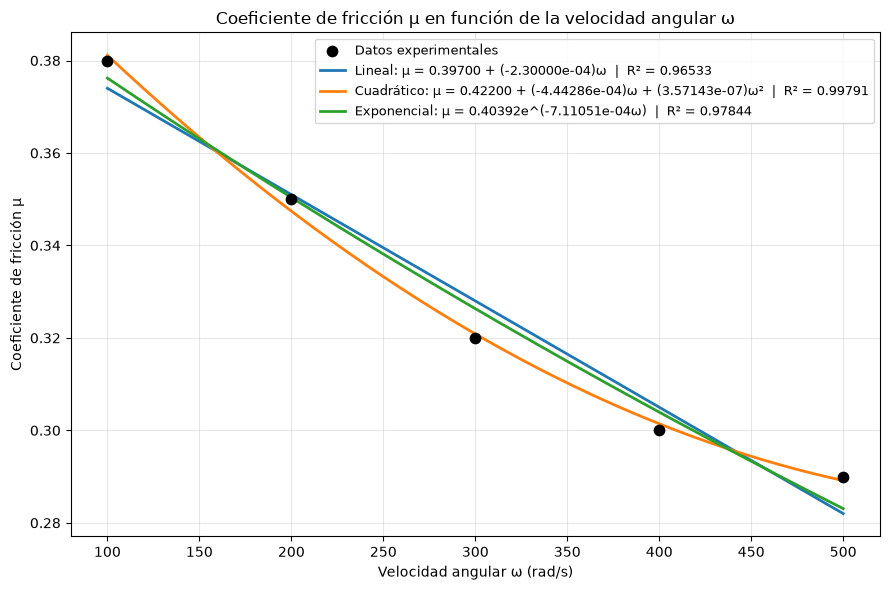

In [8]:
omega_continuo = np.linspace(omega.min(), omega.max(), 300)

mu_lineal_continuo = np.polyval(b_lineal, omega_continuo)
mu_cuadratico_continuo = np.polyval(coef_cuadratico, omega_continuo)
mu_exponencial_continuo = modelo_exponencial(omega_continuo, a_exp, b_exp)

plt.figure(figsize=(9, 6))
plt.scatter(omega, mu, color="black", s=55, label="Datos experimentales", zorder=4)
plt.plot(
    omega_continuo,
    mu_lineal_continuo,
    label=f"Lineal: μ = {intercepto:.5f} + ({pendiente:.5e})ω  |  R² = {r2_lineal:.5f}",
    linewidth=2
)
plt.plot(
    omega_continuo,
    mu_cuadratico_continuo,
    label=(f"Cuadrático: μ = {c0:.5f} + ({c1:.5e})ω "
           f"+ ({c2:.5e})ω²  |  R² = {r2_cuadratico:.5f}"),
    linewidth=2
)
plt.plot(
    omega_continuo,
    mu_exponencial_continuo,
    label=(f"Exponencial: μ = {a_exp:.5f}e^({b_exp:.5e}ω)  "
           f"|  R² = {r2_exponencial:.5f}"),
    linewidth=2
)

plt.title("Coeficiente de fricción μ en función de la velocidad angular ω")
plt.xlabel("Velocidad angular ω (rad/s)")
plt.ylabel("Coeficiente de fricción μ")
plt.grid(True, alpha=0.3)
plt.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()

# Explicación
 En este código cargo los datos experimentales de velocidad angular y fricción, programo las funciones para calcular $R^2$ y el error cuadrático medio, y realizo los ajustes lineal y cuadrático con numpy.polyfit, además del ajuste exponencial linealizando con logaritmos, para luego comparar sus métricas en una tabla y graficar las curvas sobre los puntos medidos.   

# Conclusion del caso 1
En el Caso 1, al revisar cómo cambia el coeficiente de fricción ($\mu$) cuando sube la velocidad angular ($\omega$) entre $100$ y $500\text{ rad/s}$, el ajuste cuadrático fue el que mejor quedó ($R^2 \approx 0.9979$ y $\text{ECM} \approx 2.29 \times 10^{-6}$), por encima del lineal ($R^2 \approx 0.9653$, $\text{ECM} \approx 3.80 \times 10^{-5}$) y del exponencial con curve_fit ($R^2 \approx 0.9784$, $\text{ECM} \approx 2.36 \times 10^{-5}$). Básicamente, la curva tiene una caída suave que una línea recta no logra seguir del todo bien.

# Parte A - Caso 2: pérdida de carga en una tubería

Se ajusta el modelo potencial:

$h_f = kQ^n$

donde $h_f$ es la pérdida de carga, $Q$ el caudal y $k$ y $n$ son constantes.

## Paso 1: Datos experimentales

caudal representa $Q$ en L/s y perdida_carga representa $h_f$ en metros.

In [9]:
caudal = np.array([1, 2, 3, 4, 5], dtype=float)
perdida_carga = np.array([0.2, 0.9, 2.1, 4.0, 6.3], dtype=float)

datos_caso2 = pd.DataFrame({
    "Q (L/s)": caudal,
    "h_f (m)": perdida_carga
})

datos_caso2

,Q (L/s),h_f (m)
0,1.0,0.2
1,2.0,0.9
2,3.0,2.1
3,4.0,4.0
4,5.0,6.3


## Paso 2: Linealización para obtener valores iniciales

Al aplicar logaritmos:

$\ln(h_f)=\ln(k)+n\ln(Q)$

Se obtiene una recta. La pendiente es $n$ y la ordenada al origen permite calcular $k=e^{b}$.

In [10]:
coef_log_caso2 = np.polyfit(np.log(caudal), np.log(perdida_carga), 1)
n_inicial = coef_log_caso2[0]
k_inicial = np.exp(coef_log_caso2[1])

print(f"Valor inicial de k: {k_inicial:.8f}")
print(f"Valor inicial de n: {n_inicial:.8f}")

Valor inicial de k: 0.20095941
Valor inicial de n: 2.14668665


## Paso 3: Ajuste con `curve_fit`

curve_fit ajusta directamente el modelo $h_f=kQ^n$ y calcula los parámetros que hacen mínima la suma de los residuos al cuadrado.

In [11]:
def modelo_potencial(caudal, k, n):
    return k * caudal**n

parametros_caso2, covarianza_caso2 = curve_fit(
    modelo_potencial,
    caudal,
    perdida_carga,
    p0=(k_inicial, n_inicial),
    maxfev=10000
)

k_caso2, n_caso2 = parametros_caso2
perdida_ajustada = modelo_potencial(caudal, k_caso2, n_caso2)

r2_caso2 = calcular_r2(perdida_carga, perdida_ajustada)
ecm_caso2 = calcular_ecm(perdida_carga, perdida_ajustada)

print(f"Modelo ajustado: h_f = {k_caso2:.8f}Q^{n_caso2:.8f}")
print(f"k = {k_caso2:.8f}")
print(f"n = {n_caso2:.8f}")
print(f"R² = {r2_caso2:.8f}")
print(f"ECM = {ecm_caso2:.8e}")

Modelo ajustado: h_f = 0.20855062Q^2.11980211
k = 0.20855062
n = 2.11980211
R² = 0.99975750
ECM = 1.18825143e-03


## Paso 4: Evaluar el modelo

- El $R^2$ mide qué proporción de la variación experimental explica el modelo.
- El ECM mide el error promedio al cuadrado.
- $R^2$ cercano a 1 y ECM cercano a 0 indican un ajuste bueno.

In [12]:
evaluacion_caso2 = pd.DataFrame({
    "Caudal Q (L/s)": caudal,
    "h_f experimental (m)": perdida_carga,
    "h_f ajustada (m)": perdida_ajustada,
    "Residuo (m)": perdida_carga - perdida_ajustada
})

print(f"R² = {r2_caso2:.8f}")
print(f"ECM = {ecm_caso2:.8e}")
evaluacion_caso2

R² = 0.99975750
ECM = 1.18825143e-03


,Caudal Q (L/s),h_f experimental (m),h_f ajustada (m),Residuo (m)
0,1.0,0.2,0.208551,-0.008551
1,2.0,0.9,0.906433,-0.006433
2,3.0,2.1,2.140987,-0.040987
3,4.0,4.0,3.939667,0.060333
4,5.0,6.3,6.322511,-0.022511


## Paso 5: Visualizar el ajuste

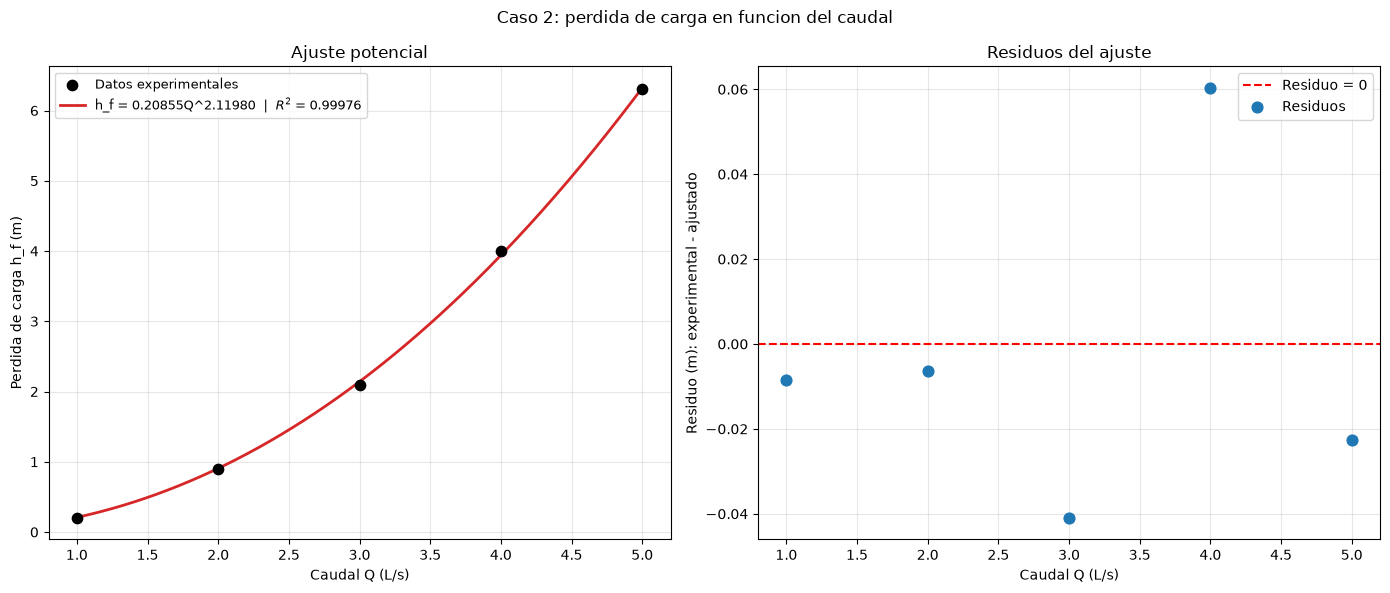

In [ ]:
residuos_caso2 = perdida_carga - perdida_ajustada
caudal_continuo = np.linspace(caudal.min(), caudal.max(), 300)
perdida_continua = modelo_potencial(caudal_continuo, k_caso2, n_caso2)

fig, (ax_ajuste, ax_residuos) = plt.subplots(1, 2, figsize=(14, 6))

ax_ajuste.scatter(
    caudal,
    perdida_carga,
    color="black",
    s=55,
    label="Datos experimentales",
    zorder=4
)
ax_ajuste.plot(
    caudal_continuo,
    perdida_continua,
    color="tab:red",
    linewidth=2,
    label=(f"h_f = {k_caso2:.5f}Q^{n_caso2:.5f}  |  "
           f"$R^2$ = {r2_caso2:.5f}")
)
ax_ajuste.set_title("Ajuste potencial")
ax_ajuste.set_xlabel("Caudal Q (L/s)")
ax_ajuste.set_ylabel("Perdida de carga h_f (m)")
ax_ajuste.grid(True, alpha=0.3)
ax_ajuste.legend(loc="best", fontsize=9)

ax_residuos.axhline(0, color="red", linestyle="--", linewidth=1.5, label="Residuo = 0")
ax_residuos.scatter(caudal, residuos_caso2, color="tab:blue", s=60, label="Residuos", zorder=3)
ax_residuos.set_title("Residuos del ajuste")
ax_residuos.set_xlabel("Caudal Q (L/s)")
ax_residuos.set_ylabel("Residuo (m): experimental - ajustado")
ax_residuos.grid(True, alpha=0.3)
ax_residuos.legend()

fig.suptitle("Caso 2: perdida de carga en funcion del caudal")
fig.tight_layout()
plt.show()
""

### Relación con la ley de Darcy-Weisbach y discusión del ajuste físico

La ecuación de Darcy–Weisbach calcula la pérdida de carga por fricción en tuberías ($h_f = f \frac{L}{D} \frac{v^2}{2g}$). Como en un tubo de diámetro constante la velocidad es proporcional al caudal, cuando el factor de fricción $f$ varía poco la pérdida crece cerca de $Q^2$. En este caso, el ajuste $h_f = 0.2086\,Q^{2.120}$ ($R^2 = 0.9998$) concuerda con esa tendencia cuadrática, aunque $f$ también puede cambiar con el flujo y la rugosidad.  

# Explicación
Aquí se uso los datos de caudal y pérdida de carga, se definio el modelo potencial $h_f = kQ^n$ y uso scipy.optimize.curve_fit para encontrar los parámetros $k$ y $n$, evaluando el ajuste y graficando la curva resultante junto con los datos experimentales


# Conlusion caso 2
En el Caso 2, con la pérdida de carga ($h_f$) según el caudal ($Q$) de $1$ a $5\text{ L/s}$ en el tubo de $25\text{ mm}$, sacar primero los valores iniciales linealizando con logaritmos ayudó bastante para que curve_fit ajustara el modelo potencial $h_f = kQ^n$ ($h_f \approx 0.2086\,Q^{2.1198}$). El ajuste dio muy bien ($R^2 \approx 0.9998$, $\text{ECM} \approx 1.19 \times 10^{-3}$) con residuos pequeños, de entre $-0.041\text{ m}$ y $0.060\text{ m}$. Además, ese exponente cercano a $2.12$ hace sentido con lo que se espera en tuberías por la relación con el cuadrado del caudal en Darcy–Weisbach, y el parámetro $k$ junta lo que corresponde a la tubería y a la fricción del tramo.

## Gráfica de residuos del Caso 2

El residuo se calcula como valor experimental menos valor ajustado. La línea horizontal en cero ayuda a ver si los errores se distribuyen alrededor del modelo.

# Parte B: Interpolación numérica - Caso 3

## Propiedades térmicas de un metal

Se interpolan los datos de conductividad térmica $k(T)$ en función de la temperatura $T$.

## Paso 1: Datos experimentales

La temperatura se expresa en grados Celsius y la conductividad en W/(m·K).

In [14]:
temperatura = np.array([100, 200, 300, 400, 500], dtype=float)
conductividad = np.array([180, 150, 130, 120, 115], dtype=float)

datos_caso3 = pd.DataFrame({
    "T (°C)": temperatura,
    "k (W/(m·K))": conductividad
})

datos_caso3


,T (°C),k (W/(m·K))
0,100.0,180.0
1,200.0,150.0
2,300.0,130.0
3,400.0,120.0
4,500.0,115.0


## Paso 2: Interpolación polinómica directa

Con cinco puntos se construye un polinomio de grado cuatro. np.polyfit obtiene sus coeficientes y np.polyval evalúa el polinomio. Al tratarse de una interpolación, este pasa por los cinco puntos (salvo pequeño error de redondeo numérico).

In [15]:
coef_interpolacion = np.polyfit(temperatura, conductividad, 4)
conductividad_directa = np.polyval(coef_interpolacion, temperatura)

print("Coeficientes del polinomio (de mayor a menor grado):")
print(coef_interpolacion)
print()
print("Valores interpolados en los puntos originales:")
print(conductividad_directa)


Coeficientes del polinomio (de mayor a menor grado):
[-2.08333333e-09  2.08333333e-06 -2.29166667e-04 -3.45833333e-01
  2.15000000e+02]

Valores interpolados en los puntos originales:
[180. 150. 130. 120. 115.]


## Paso 3: Método de Lagrange para estimar $k(250°C)$

Lagrange construye una suma de polinomios base, cada uno vale 1 en su propio dato y 0 en los demás. Así el polinomio resultante pasa por todos los puntos experimentales.

In [16]:
def interpolar_lagrange(x_datos, y_datos, x_eval):
    resultado = 0.0
    for i in range(len(x_datos)):
        base = 1.0
        for j in range(len(x_datos)):
            if i != j:
                base *= (x_eval - x_datos[j]) / (x_datos[i] - x_datos[j])
        resultado += y_datos[i] * base
    return resultado

k_lagrange_250 = interpolar_lagrange(temperatura, conductividad, 250)
print(f"Estimacion de k(250 C) por Lagrange: {k_lagrange_250:.8f} W/(m K)")


Estimacion de k(250 C) por Lagrange: 138.63281250 W/(m K)


## Paso 4: Diferencias divididas de Newton

La primera columna contiene los valores medidos. Las siguientes columnas contienen diferencias divididas de orden creciente; la primera fila de cada orden proporciona los coeficientes del polinomio de Newton.

In [17]:
cantidad_puntos = len(temperatura)
tabla_diferencias = np.full((cantidad_puntos, cantidad_puntos), np.nan)
tabla_diferencias[:, 0] = conductividad

for orden in range(1, cantidad_puntos):
    for i in range(cantidad_puntos - orden):
        numerador = tabla_diferencias[i + 1, orden - 1] - tabla_diferencias[i, orden - 1]
        denominador = temperatura[i + orden] - temperatura[i]
        tabla_diferencias[i, orden] = numerador / denominador

nombres_columnas = ["f[T_i]"] + [f"Orden {j}" for j in range(1, cantidad_puntos)]
tabla_newton = pd.DataFrame(tabla_diferencias, columns=nombres_columnas)
tabla_newton.index = [f"T{i} = {valor:.0f} C" for i, valor in enumerate(temperatura)]
tabla_newton


,f[T_i],Orden 1,Orden 2,Orden 3,Orden 4
T0 = 100 C,180.0,-0.30,0.00050,3.614007e-22,-2.083333e-09
T1 = 200 C,150.0,-0.20,0.00050,-8.333333e-07,NaN
T2 = 300 C,130.0,-0.10,0.00025,NaN,NaN
T3 = 400 C,120.0,-0.05,NaN,NaN,NaN
T4 = 500 C,115.0,NaN,NaN,NaN,NaN


In [18]:
def interpolar_newton(x_datos, tabla, x_eval):
    resultado = tabla[0, 0]
    producto = 1.0
    for orden in range(1, len(x_datos)):
        producto *= x_eval - x_datos[orden - 1]
        resultado += tabla[0, orden] * producto
    return resultado

k_newton_250 = interpolar_newton(temperatura, tabla_diferencias, 250)
print(f"Estimacion de k(250 C) por Newton: {k_newton_250:.8f} W/(m K)")


Estimacion de k(250 C) por Newton: 138.63281250 W/(m K)


## Paso 5: Comparar metodos y validar con `np.polyfit`

Se evalúa el polinomio directo de np.polyfit en $250°C$ y se compara con las estimaciones de Lagrange y Newton.

In [19]:
k_directa_250 = np.polyval(coef_interpolacion, 250)
comparacion_caso3 = pd.DataFrame({
    "Metodo": ["np.polyfit", "Lagrange", "Newton"],
    "k(250 C) (W/(m K))": [k_directa_250, k_lagrange_250, k_newton_250]
})

print("Diferencia maxima entre metodos:", max(
    abs(k_directa_250 - k_lagrange_250),
    abs(k_directa_250 - k_newton_250),
    abs(k_lagrange_250 - k_newton_250)
))
assert np.allclose([k_directa_250, k_lagrange_250], k_newton_250, rtol=1e-10, atol=1e-10)
comparacion_caso3


Diferencia maxima entre metodos: 5.684341886080802e-14


,Metodo,k(250 C) (W/(m K))
0,np.polyfit,138.632812
1,Lagrange,138.632812
2,Newton,138.632812


## Paso 6: Graficar y analizar el polinomio interpolante

Se traza el polinomio dentro del intervalo de los datos. El fenómeno de Runge se refiere a oscilaciones que pueden aparecer al usar polinomios de grado alto, especialmente cerca de los extremos. Con estos cinco puntos y un polinomio de grado cuatro, se debe observar la curva y no extrapolar fuera del intervalo medido.

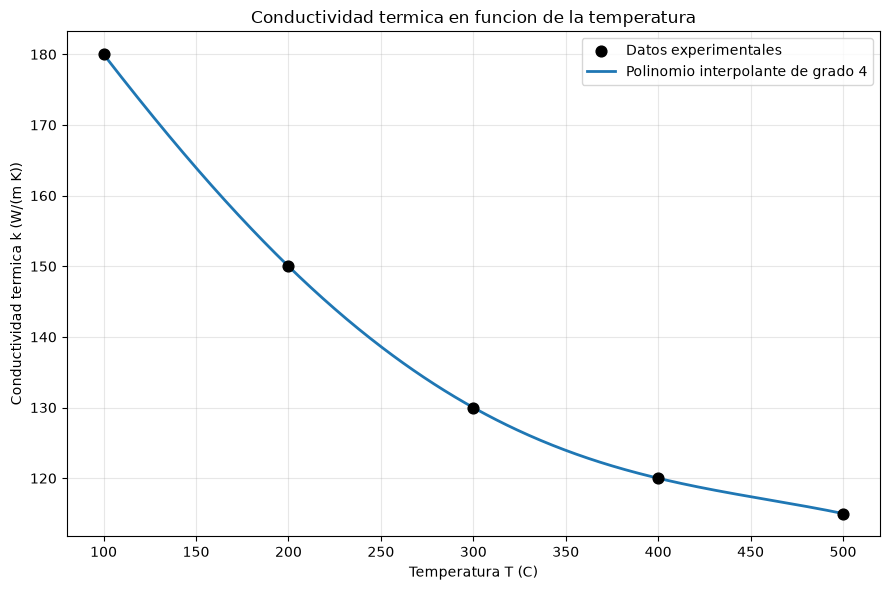

In [20]:
temperatura_continua = np.linspace(temperatura.min(), temperatura.max(), 500)
conductividad_continua = np.polyval(coef_interpolacion, temperatura_continua)

plt.figure(figsize=(9, 6))
plt.scatter(temperatura, conductividad, color="black", s=60, label="Datos experimentales", zorder=3)
plt.plot(temperatura_continua, conductividad_continua, color="tab:blue", linewidth=2,
         label="Polinomio interpolante de grado 4")
plt.title("Conductividad termica en funcion de la temperatura")
plt.xlabel("Temperatura T (C)")
plt.ylabel("Conductividad termica k (W/(m K))")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


- El polinomio de grado 4 pasa exactamente por los 5 puntos experimentales y reproduce la caída suave de $k(T)$.   

- Fenómeno de Runge: Al interpolar con polinomios de grado alto sobre nodos equiespaciados, pueden surgir oscilaciones no físicas (sobre todo hacia los extremos o fuera del intervalo medido). En este caso de grado 4 no se aprecian oscilaciones severas dentro de [100, 500] °C, pero debe vigilarse si se extrapolan temperaturas o se añaden más nodos equiespaciados.

# Explicación
En esta parte se usan funciones para resolver la interpolación directa, el polinomio de Lagrange y las diferencias divididas de Newton con los datos de temperatura y conductividad térmica,se muestra la tabla de diferencias divididas, se evalua en 250°C  y grafica el polinomio interpolante comparándolo con un ajuste de numpy.polyfit para observar el comportamiento y el fenómeno de Runge.

# Conclusion caso 3
En el Caso 3, la interpolación con Vandermonde ajusta un polinomio de grado 5 que pasa exacto por todos los puntos de $v(t)$ (incluido $v(0) = 0$), estima $v(16) \approx 392.19\text{ m/s}$ y grafica de $0$ a $35\text{ s}$. A diferencia de los ajustes por regresión anteriores, no tiene error en los datos medidos, pero requiere precaución al extrapolar o cambiar de grado